In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [4]:
df = pd.read_csv(r"../../Dataset/NF-CICIDS2018-v3.csv", low_memory=False)
df.head(5)

,FLOW_START_MILLISECONDS,FLOW_END_MILLISECONDS,IPV4_SRC_ADDR,L4_SRC_PORT,IPV4_DST_ADDR,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,IN_PKTS,...,SRC_TO_DST_IAT_MIN,SRC_TO_DST_IAT_MAX,SRC_TO_DST_IAT_AVG,SRC_TO_DST_IAT_STDDEV,DST_TO_SRC_IAT_MIN,DST_TO_SRC_IAT_MAX,DST_TO_SRC_IAT_AVG,DST_TO_SRC_IAT_STDDEV,Label,Attack
0,1518611287705,1518611287705,172.31.0.2,53,172.31.66.58,63593,17,5,156,1,...,0,0,0,0,0,0,0,0,0,Benign
1,1518611287743,1518611290747,172.31.66.58,56163,239.255.255.250,1900,17,12,805,5,...,0,2793,750,1182,0,0,0,0,0,Benign
2,1518611288143,1518611300202,172.31.66.46,62388,239.255.255.250,1900,17,12,1288,8,...,0,3016,1722,1436,0,0,0,0,0,Benign
3,1518611288165,1518611336194,0.0.0.0,546,0.0.0.0,547,17,103,393,3,...,16014,32014,24014,8000,0,0,0,0,0,Benign
4,1518611288175,1518611288176,172.31.66.46,49187,169.254.169.254,80,6,7,373,5,...,0,0,0,0,0,0,0,0,0,Benign


In [5]:
df.shape

(20115529, 55)

In [8]:
df.describe()

,FLOW_START_MILLISECONDS,FLOW_END_MILLISECONDS,L4_SRC_PORT,L4_DST_PORT,PROTOCOL,L7_PROTO,IN_BYTES,IN_PKTS,OUT_BYTES,OUT_PKTS,...,FTP_COMMAND_RET_CODE,SRC_TO_DST_IAT_MIN,SRC_TO_DST_IAT_MAX,SRC_TO_DST_IAT_AVG,SRC_TO_DST_IAT_STDDEV,DST_TO_SRC_IAT_MIN,DST_TO_SRC_IAT_MAX,DST_TO_SRC_IAT_AVG,DST_TO_SRC_IAT_STDDEV,Label
count,2.011553e+07,2.011553e+07,2.011553e+07,2.011553e+07,2.011553e+07,2.011553e+07,2.011553e+07,2.011553e+07,2.011553e+07,2.011553e+07,...,20115529.0,2.011553e+07,2.011553e+07,2.011553e+07,2.011553e+07,2.011553e+07,2.011553e+07,2.011553e+07,2.011553e+07,2.011553e+07
mean,1.519309e+12,1.519309e+12,5.009062e+04,2.527545e+03,1.024936e+01,3.830512e+01,2.295718e+03,3.132480e+01,5.363537e+03,8.010206e+00,...,0.0,1.198082e+02,4.452214e+03,1.103057e+03,1.579613e+03,4.273024e+02,3.999819e+03,1.212043e+03,1.279235e+03,1.292983e-01
std,4.679144e+08,4.679141e+08,1.548064e+04,8.251328e+03,5.554124e+00,4.343755e+01,1.090547e+05,1.772182e+03,2.653292e+05,1.817949e+02,...,0.0,1.703411e+03,1.301782e+04,3.320838e+03,4.662761e+03,4.098247e+03,1.263543e+04,4.843394e+03,4.228844e+03,3.355298e-01
min,1.518611e+12,1.518611e+12,0.000000e+00,0.000000e+00,1.000000e+00,0.000000e+00,2.800000e+01,1.000000e+00,0.000000e+00,0.000000e+00,...,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.518804e+12,1.518804e+12,5.024400e+04,5.300000e+01,6.000000e+00,5.000000e+00,6.700000e+01,1.000000e+00,9.200000e+01,1.000000e+00,...,0.0,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,1.519247e+12,1.519247e+12,5.326000e+04,8.000000e+01,6.000000e+00,7.000000e+00,1.460000e+02,3.000000e+00,1.920000e+02,2.000000e+00,...,0.0,0.000000e+00,2.500000e+01,1.500000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
75%,1.519835e+12,1.519835e+12,5.878500e+04,4.450000e+02,1.700000e+01,8.800000e+01,1.120000e+03,8.000000e+00,1.721000e+03,7.000000e+00,...,0.0,1.000000e+00,1.179000e+03,3.140000e+02,3.590000e+02,0.000000e+00,9.530000e+02,3.280000e+02,2.970000e+02,0.000000e+00
max,1.520021e+12,1.520021e+12,6.553500e+04,6.553500e+04,5.800000e+01,4.010000e+02,1.859742e+07,3.099570e+05,1.664690e+08,1.231170e+05,...,0.0,6.094700e+04,6.097000e+04,6.094700e+04,3.040300e+04,6.093500e+04,6.093500e+04,6.093500e+04,3.034300e+04,1.000000e+00


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20115529 entries, 0 to 20115528
Data columns (total 55 columns):
 #   Column                       Dtype 
---  ------                       ----- 
 0   FLOW_START_MILLISECONDS      int64 
 1   FLOW_END_MILLISECONDS        int64 
 2   IPV4_SRC_ADDR                object
 3   L4_SRC_PORT                  int64 
 4   IPV4_DST_ADDR                object
 5   L4_DST_PORT                  int64 
 6   PROTOCOL                     int64 
 7   L7_PROTO                     int64 
 8   IN_BYTES                     int64 
 9   IN_PKTS                      int64 
 10  OUT_BYTES                    int64 
 11  OUT_PKTS                     int64 
 12  TCP_FLAGS                    int64 
 13  CLIENT_TCP_FLAGS             int64 
 14  SERVER_TCP_FLAGS             int64 
 15  FLOW_DURATION_MILLISECONDS   int64 
 16  DURATION_IN                  int64 
 17  DURATION_OUT                 int64 
 18  MIN_TTL                      int64 
 19  MAX_TTL            

In [9]:
df.isnull().sum()

FLOW_START_MILLISECONDS        0
FLOW_END_MILLISECONDS          0
IPV4_SRC_ADDR                  0
L4_SRC_PORT                    0
IPV4_DST_ADDR                  0
L4_DST_PORT                    0
PROTOCOL                       0
L7_PROTO                       0
IN_BYTES                       0
IN_PKTS                        0
OUT_BYTES                      0
OUT_PKTS                       0
TCP_FLAGS                      0
CLIENT_TCP_FLAGS               0
SERVER_TCP_FLAGS               0
FLOW_DURATION_MILLISECONDS     0
DURATION_IN                    0
DURATION_OUT                   0
MIN_TTL                        0
MAX_TTL                        0
LONGEST_FLOW_PKT               0
SHORTEST_FLOW_PKT              0
MIN_IP_PKT_LEN                 0
MAX_IP_PKT_LEN                 0
SRC_TO_DST_SECOND_BYTES        0
DST_TO_SRC_SECOND_BYTES        0
RETRANSMITTED_IN_BYTES         0
RETRANSMITTED_IN_PKTS          0
RETRANSMITTED_OUT_BYTES        0
RETRANSMITTED_OUT_PKTS         0
SRC_TO_DST

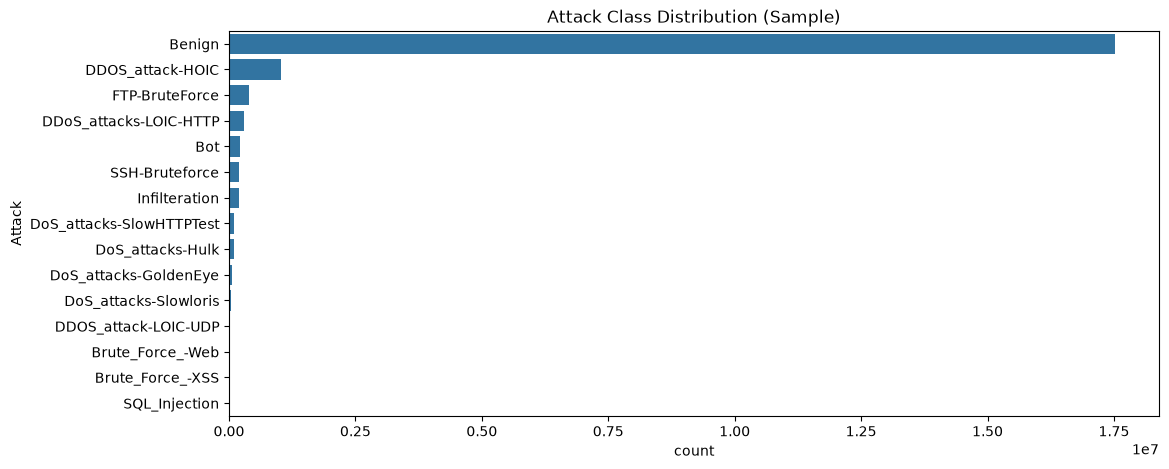

Attack
Benign                      87.07
DDOS_attack-HOIC             5.13
FTP-BruteForce               1.92
DDoS_attacks-LOIC-HTTP       1.43
Bot                          1.03
SSH-Bruteforce               0.94
Infilteration                0.94
DoS_attacks-SlowHTTPTest     0.52
DoS_attacks-Hulk             0.50
DoS_attacks-GoldenEye        0.30
DoS_attacks-Slowloris        0.18
DDOS_attack-LOIC-UDP         0.02
Brute_Force_-Web             0.01
Brute_Force_-XSS             0.00
SQL_Injection                0.00
Name: proportion, dtype: float64


In [10]:
plt.figure(figsize=(12,5))
order = df["Attack"].value_counts().index
sns.countplot(data=df, y="Attack", order=order)
plt.title("Attack Class Distribution (Sample)")
plt.show()

print(df["Attack"].value_counts(normalize=True).mul(100).round(2))

In [11]:

# 1. Downcast integers one column at a time (In-place)
for col in df.select_dtypes(include=['int64']).columns:
    df[col] = pd.to_numeric(df[col], downcast='integer')

# 2. Downcast floats one column at a time (In-place)
for col in df.select_dtypes(include=['float64']).columns:
    df[col] = pd.to_numeric(df[col], downcast='float')

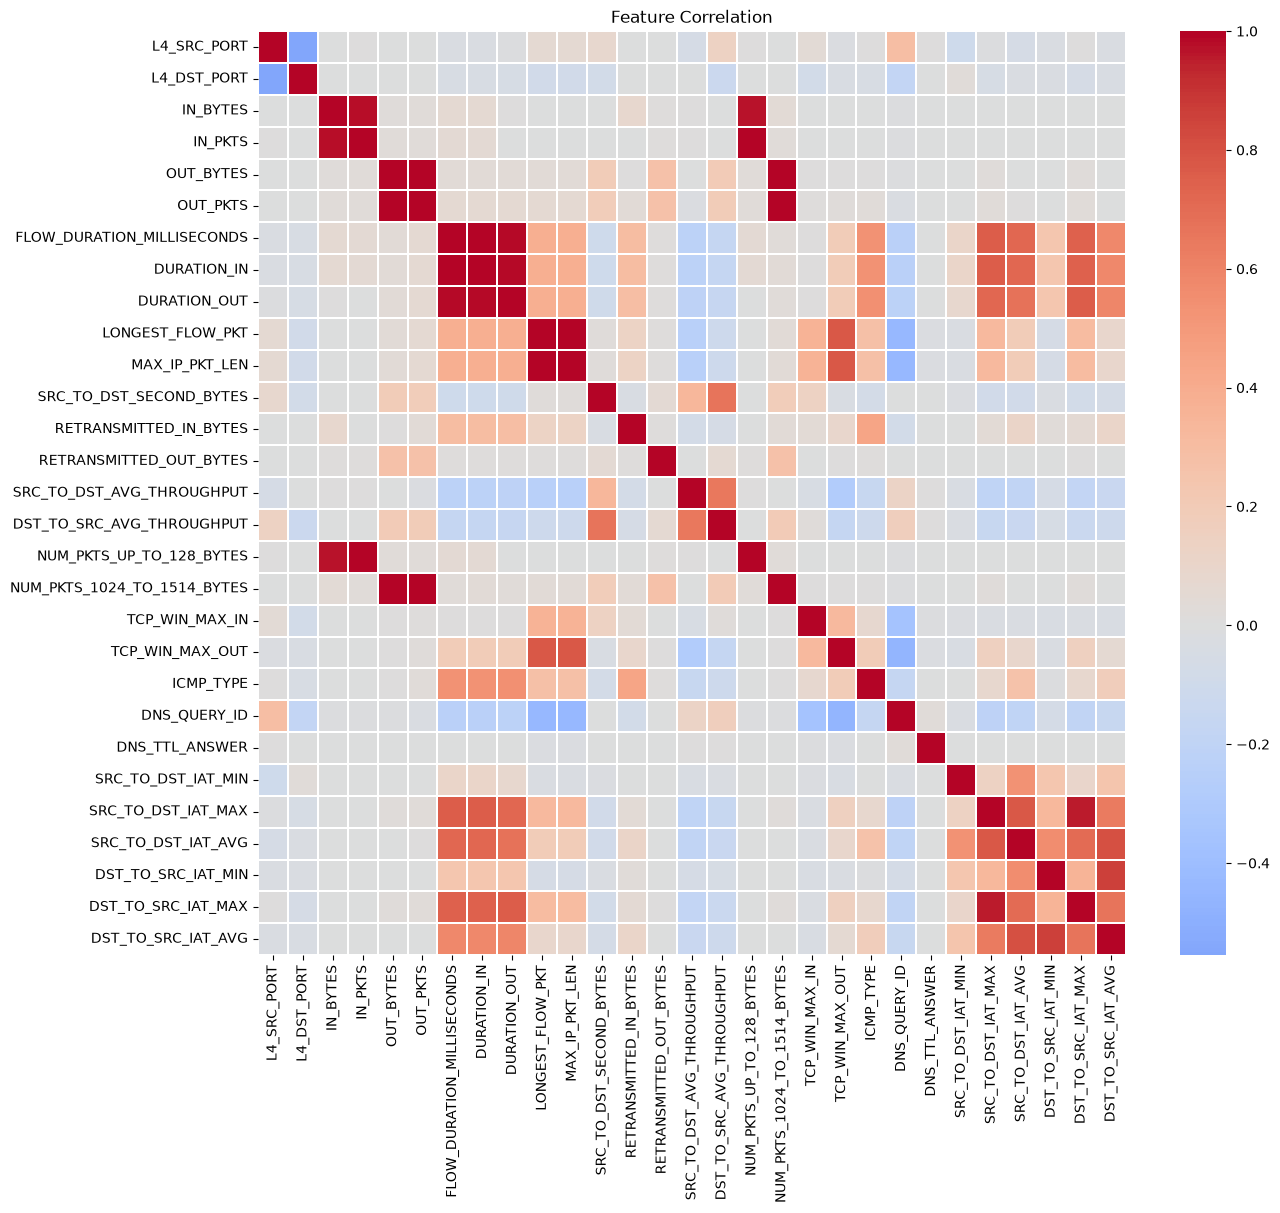

In [12]:
num_cols = df.select_dtypes(include=["int32","float32"]).columns.tolist()
# remove Label if present
corr = df[num_cols].corr()

plt.figure(figsize=(14,12))
sns.heatmap(corr, cmap="coolwarm", center=0, linewidths=0.3)
plt.title("Feature Correlation")
plt.show()

In [13]:
drop_cols = [
    'IPV4_SRC_ADDR', 'IPV4_DST_ADDR',
    'L4_SRC_PORT',
    'DNS_QUERY_ID'         # keep 'Label' as binary target
]
# Optionally also:
# drop_cols += ['L4_DST_PORT']          # if you don't bin it
# drop_cols += ['CLIENT_TCP_FLAGS', 'SERVER_TCP_FLAGS']  # if corr with TCP_FLAGS > 0.95

df.drop(columns=drop_cols,inplace=True)
# y = df['Label']   # binary 0/1 target

In [14]:
df.shape

(20115529, 51)

In [15]:
# 1. Near-zero-variance columns (e.g., a column that's 99.9% one value)
from sklearn.feature_selection import VarianceThreshold
near_zero = [c for c in df.columns if df[c].value_counts(normalize=True).iloc[0] > 0.999]

# 2. Highly correlated pairs (|r| > 0.95) — keep one
corr = df.select_dtypes('number').corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high_corr_drop = [c for c in upper.columns if any(upper[c] > 0.95)]

# 3. All-NaN or all-zero columns
all_zero_or_nan = [c for c in df.columns if (df[c].fillna(-1) == df[c].iloc[0]).all()]

In [16]:
# 1. Select only numeric columns (correlation requires numbers)
numeric_df = df.select_dtypes(include=['number'])

# 2. Calculate correlation of all numeric columns with 'Label'
# We drop 'Label' itself from the result to avoid a perfect 1.0 correlation
corr_with_label = numeric_df.corr()['Label'].drop('Label')

# 3. Sort by absolute value to see the strongest relationships first
sorted_corr = corr_with_label.abs().sort_values(ascending=False)

print("--- Correlation of Features with 'Label' ---")
print(sorted_corr)

--- Correlation of Features with 'Label' ---
TCP_WIN_MAX_IN                 0.548551
TCP_FLAGS                      0.281041
CLIENT_TCP_FLAGS               0.266486
PROTOCOL                       0.262113
L7_PROTO                       0.216591
NUM_PKTS_512_TO_1024_BYTES     0.141911
MAX_IP_PKT_LEN                 0.137885
LONGEST_FLOW_PKT               0.137885
FLOW_END_MILLISECONDS          0.135119
FLOW_START_MILLISECONDS        0.135114
SHORTEST_FLOW_PKT              0.122044
DST_TO_SRC_SECOND_BYTES        0.118396
SRC_TO_DST_SECOND_BYTES        0.114013
MIN_TTL                        0.110444
MAX_TTL                        0.109805
NUM_PKTS_256_TO_512_BYTES      0.109118
DST_TO_SRC_IAT_MAX             0.099380
DST_TO_SRC_IAT_STDDEV          0.095180
DURATION_OUT                   0.092653
DNS_QUERY_TYPE                 0.086701
NUM_PKTS_128_TO_256_BYTES      0.082159
MIN_IP_PKT_LEN                 0.078293
L4_DST_PORT                    0.076556
SERVER_TCP_FLAGS               0.07

In [17]:
# Check if every single row matches perfectly
are_identical = df['MAX_IP_PKT_LEN'].equals(df['LONGEST_FLOW_PKT'])
print(f"Are the columns exact duplicates? {are_identical}")

# Alternatively, count how many rows are different
differences = (df['MAX_IP_PKT_LEN'] != df['LONGEST_FLOW_PKT']).sum()
print(f"Number of rows where they differ: {differences} out of {len(df)}")


Are the columns exact duplicates? True
Number of rows where they differ: 0 out of 20115529


In [20]:
# List of columns to drop based on redundancy and low correlation
cols_to_drop = [
    'LONGEST_FLOW_PKT',            # Redundant with MAX_IP_PKT_LEN
    'FTP_COMMAND_RET_CODE',  
    'DNS_TTL_ANSWER' ,               
    'SRC_TO_DST_IAT_MIN',             
'NUM_PKTS_1024_TO_1514_BYTE',    
'OUT_BYTES',                     
'RETRANSMITTED_OUT_BYTE',      
'OUT_PKTS'                      
      
]

# Drop the columns from your DataFrame (replace 'df' with your variable name)
df.drop(columns=cols_to_drop, inplace=True, errors='ignore')


In [21]:
df.shape

(20115529, 45)

In [22]:
# 1. Isolate numeric columns
numeric_cols = df.select_dtypes(include=['number']).columns

# 2. Calculate skewness (Pandas handles this efficiently even on large datasets)
skewness_values = df[numeric_cols].skew().sort_values(ascending=False)

# 3. Display as a clean DataFrame
skew_df = pd.DataFrame({'Column': skewness_values.index, 'Skewness': skewness_values.values})
print("--- Skewness of All Numeric Columns ---")
print(skew_df.to_string(index=False))

--- Skewness of All Numeric Columns ---
                     Column    Skewness
    RETRANSMITTED_OUT_BYTES 1656.030215
     RETRANSMITTED_OUT_PKTS 1590.454197
     RETRANSMITTED_IN_BYTES  482.794869
NUM_PKTS_1024_TO_1514_BYTES  184.724911
 NUM_PKTS_512_TO_1024_BYTES  127.446900
                    IN_PKTS   75.423926
   NUM_PKTS_UP_TO_128_BYTES   75.415060
                   IN_BYTES   74.325450
  NUM_PKTS_128_TO_256_BYTES   53.680298
  NUM_PKTS_256_TO_512_BYTES   51.072605
  DST_TO_SRC_AVG_THROUGHPUT   48.667871
    SRC_TO_DST_SECOND_BYTES   38.855533
          SHORTEST_FLOW_PKT   18.071470
         DST_TO_SRC_IAT_MIN   13.215427
             DNS_QUERY_TYPE   12.351235
         DST_TO_SRC_IAT_AVG    8.471562
         SRC_TO_DST_IAT_AVG    6.475538
  SRC_TO_DST_AVG_THROUGHPUT    6.117954
    DST_TO_SRC_SECOND_BYTES    5.491454
                L4_DST_PORT    5.084235
      RETRANSMITTED_IN_PKTS    5.013662
      DST_TO_SRC_IAT_STDDEV    4.255644
         DST_TO_SRC_IAT_MAX    3.794856


In [23]:
from sklearn.preprocessing import RobustScaler

# Select numeric columns except the target column
numeric_cols = df.select_dtypes(include=np.number).columns.drop(
    "Label", errors="ignore"
)

# Log transformation: requires non-negative values
if (df[numeric_cols] < 0).any().any():
    raise ValueError("Negative values found. log1p cannot be applied safely.")

df[numeric_cols] = np.log1p(df[numeric_cols])

# Robust scaling
scaler = RobustScaler()
df[numeric_cols] = scaler.fit_transform(df[numeric_cols])

print("Transformation and RobustScaler applied successfully.")
print(df.head())

Transformation and RobustScaler applied successfully.
   FLOW_START_MILLISECONDS  FLOW_END_MILLISECONDS  L4_DST_PORT  PROTOCOL  \
0                -0.616766              -0.616777     3.157161       1.0   
1                -0.616766              -0.616774     1.494640       1.0   
2                -0.616766              -0.616765     1.494640       1.0   
3                -0.616766              -0.616730     0.905506       1.0   
4                -0.616766              -0.616776     0.000000       0.0   

   L7_PROTO  IN_BYTES   IN_PKTS  TCP_FLAGS  CLIENT_TCP_FLAGS  \
0 -0.106672  0.023484 -0.460845  -0.589224         -0.564944   
1  0.180026  0.607197  0.269577  -0.589224         -0.564944   
2  0.180026  0.774742  0.539155  -0.589224         -0.564944   
3  0.951081  0.351804  0.000000  -0.589224         -0.564944   
4  0.000000  0.333214  0.269577   0.028580          0.053382   

   SERVER_TCP_FLAGS  ...  DNS_QUERY_TYPE  SRC_TO_DST_IAT_MAX  \
0         -0.913666  ...             1.0

In [24]:
# Count occurrences of 0 and 1 in Label
print(df["Label"].value_counts().reindex([0, 1], fill_value=0))

# Count and percentage
print("\nLabel distribution:")
print(df["Label"].value_counts(normalize=False).reindex([0, 1], fill_value=0))

print("\nPercentage distribution:")
print(
    (df["Label"].value_counts(normalize=True) * 100)
    .reindex([0, 1], fill_value=0)
    .round(2)
)

Label
0    17514626
1     2600903
Name: count, dtype: int64

Label distribution:
Label
0    17514626
1     2600903
Name: count, dtype: int64

Percentage distribution:
Label
0    87.07
1    12.93
Name: proportion, dtype: float64


In [25]:
np.isinf(df.select_dtypes(include=[np.number])).values.sum()

np.int64(0)

In [26]:
# If you still have the raw df with string Attack labels:
counts = df['Attack'].value_counts()
print(counts)

Attack
Benign                      17514626
DDOS_attack-HOIC             1032311
FTP-BruteForce                386720
DDoS_attacks-LOIC-HTTP        288589
Bot                           207703
SSH-Bruteforce                188474
Infilteration                 188152
DoS_attacks-SlowHTTPTest      105550
DoS_attacks-Hulk              100076
DoS_attacks-GoldenEye          61300
DoS_attacks-Slowloris          36040
DDOS_attack-LOIC-UDP            3450
Brute_Force_-Web                1618
Brute_Force_-XSS                 480
SQL_Injection                    440
Name: count, dtype: int64


In [27]:
df.drop(columns=['Label'], inplace=True)

In [30]:

import pandas as pd
import numpy as np

from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE

# ============================================================
# STEP 1: Separate features and target
# ============================================================

target_col = "Attack"

if target_col not in df.columns:
    raise ValueError("The 'Attack' column is missing.")

had_label = "Label" in df.columns

X = df.drop(
    columns=["Attack", "Label"],
    errors="ignore"
).copy()

y = df["Attack"].copy()

print("Original dataset shape:", df.shape)
print("\nOriginal class distribution:")
print(y.value_counts())


# ============================================================
# STEP 2: Define target counts using your actual classes
# ============================================================

target_counts = {
    "Benign": 1_500_000,
    "DDOS_attack-HOIC": 1_032_311,
    "FTP-BruteForce": 386_720,
    "DDoS_attacks-LOIC-HTTP": 308_589,
    "Bot": 227_703,
    "SSH-Bruteforce": 188_474,
    "Infilteration": 188_152,
    "DoS_attacks-SlowHTTPTest": 105_550,
    "DoS_attacks-Hulk": 100_076,
    "DoS_attacks-GoldenEye": 61_300,
    "DoS_attacks-Slowloris": 36_040,
    "DDOS_attack-LOIC-UDP": 30_000,
    "Brute_Force_-Web": 5_000,
    "Brute_Force_-XSS": 5_000,
    "SQL_Injection": 5_000
}

missing_classes = set(target_counts) - set(y.unique())

if missing_classes:
    raise ValueError(
        f"Classes missing from dataset: {missing_classes}"
    )

# Check feature types
non_numeric_cols = X.select_dtypes(
    exclude=np.number
).columns.tolist()

if non_numeric_cols:
    raise ValueError(
        "Encode or remove categorical features before SMOTE: "
        f"{non_numeric_cols}"
    )

# Check missing and infinite values
if not np.isfinite(X.to_numpy(dtype=np.float64)).all():
    raise ValueError(
        "Missing or infinite feature values detected. "
        "Clean them before resampling."
    )


# ============================================================
# STEP 3: Undersample majority classes
# ============================================================

current_counts = y.value_counts()

under_strategy = {
    cls: target
    for cls, target in target_counts.items()
    if current_counts[cls] > target
}

if under_strategy:
    under_sampler = RandomUnderSampler(
        sampling_strategy=under_strategy,
        random_state=42
    )

    X_under, y_under = under_sampler.fit_resample(X, y)
else:
    X_under, y_under = X.copy(), y.copy()

print("\nAfter undersampling:")
print(y_under.value_counts())


# ============================================================
# STEP 4: Oversample minority classes with SMOTE
# ============================================================

counts_after_under = y_under.value_counts()

smote_strategy = {
    cls: target
    for cls, target in target_counts.items()
    if counts_after_under[cls] < target
}

# SMOTE requires at least k_neighbors + 1 examples per class
for cls in smote_strategy:
    if counts_after_under[cls] <= 5:
        raise ValueError(
            f"{cls} has too few samples for k_neighbors=5."
        )

if smote_strategy:
    smote = SMOTE(
        sampling_strategy=smote_strategy,
        random_state=42,
        k_neighbors=5
    )

    X_resampled, y_resampled = smote.fit_resample(
        X_under, y_under
    )
else:
    X_resampled, y_resampled = X_under, y_under


# ============================================================
# STEP 5: Reconstruct dataset
# ============================================================

df_resampled = pd.DataFrame(
    X_resampled,
    columns=X.columns
)

df_resampled["Attack"] = np.asarray(y_resampled)

# Reconstruct binary Label:
# Benign = 0, all attack classes = 1
if had_label:
    df_resampled["Label"] = (
        df_resampled["Attack"] != "Benign"
    ).astype("int8")


# ============================================================
# STEP 6: Verify class counts and percentages
# ============================================================

print("\nFinal class distribution:")
print(df_resampled["Attack"].value_counts())

print("\nFinal class distribution (%):")
print(
    (
        df_resampled["Attack"].value_counts(normalize=True)
        * 100
    ).round(2)
)

print("\nFinal dataset shape:", df_resampled.shape)

actual_counts = df_resampled["Attack"].value_counts()

for cls, target in target_counts.items():
    assert actual_counts[cls] == target, (
        f"{cls}: expected {target}, "
        f"got {actual_counts[cls]}"
    )

print("\nAll target counts verified successfully.")


# ============================================================
# STEP 7: Save dataset
# ============================================================

output_file = "NF-CICIDS2018-V3-SMOTE.csv"

df_resampled.to_csv(output_file, index=False)

print(f"\nSaved successfully: {output_file}")

Original dataset shape: (20115529, 44)

Original class distribution:
Attack
Benign                      17514626
DDOS_attack-HOIC             1032311
FTP-BruteForce                386720
DDoS_attacks-LOIC-HTTP        288589
Bot                           207703
SSH-Bruteforce                188474
Infilteration                 188152
DoS_attacks-SlowHTTPTest      105550
DoS_attacks-Hulk              100076
DoS_attacks-GoldenEye          61300
DoS_attacks-Slowloris          36040
DDOS_attack-LOIC-UDP            3450
Brute_Force_-Web                1618
Brute_Force_-XSS                 480
SQL_Injection                    440
Name: count, dtype: int64

After undersampling:
Attack
Benign                      1500000
DDOS_attack-HOIC            1032311
FTP-BruteForce               386720
DDoS_attacks-LOIC-HTTP       288589
Bot                          207703
SSH-Bruteforce               188474
Infilteration                188152
DoS_attacks-SlowHTTPTest     105550
DoS_attacks-Hulk          

In [31]:
 df1 = pd.read_csv(r"NF-CICIDS2018-V3-SMOTE.csv", low_memory=False)

In [32]:
df1.shape

(4179915, 44)

## datapoint after sampaling

In [33]:
class_counts = df1["Attack"].value_counts()

class_distribution = pd.DataFrame({
    "Count": class_counts,
    "Percentage (%)": (
        df1["Attack"]
        .value_counts(normalize=True) * 100
    ).round(2)
})

print(class_distribution)

                            Count  Percentage (%)
Attack                                           
Benign                    1500000           35.89
DDOS_attack-HOIC          1032311           24.70
FTP-BruteForce             386720            9.25
DDoS_attacks-LOIC-HTTP     308589            7.38
Bot                        227703            5.45
SSH-Bruteforce             188474            4.51
Infilteration              188152            4.50
DoS_attacks-SlowHTTPTest   105550            2.53
DoS_attacks-Hulk           100076            2.39
DoS_attacks-GoldenEye       61300            1.47
DoS_attacks-Slowloris       36040            0.86
DDOS_attack-LOIC-UDP        30000            0.72
Brute_Force_-Web             5000            0.12
Brute_Force_-XSS             5000            0.12
SQL_Injection                5000            0.12


In [34]:
pwd

'/data/aicoe_gpu/sayantan_singha_roy_ek3/fl-ids/src/EDA'

In [ ]:
/src/EDA/NF-CICIDS2018-V3-SMOTE.csv